# Cvičenie I - Úvod a časové rady I

## 1. Načítanie datasetu a knižníc

Pracujeme s datasetom, v ktorom sú pozorovania zaznamenávané v pravidelných časových intervaloch, teda s rovnakým časovým odstupom.

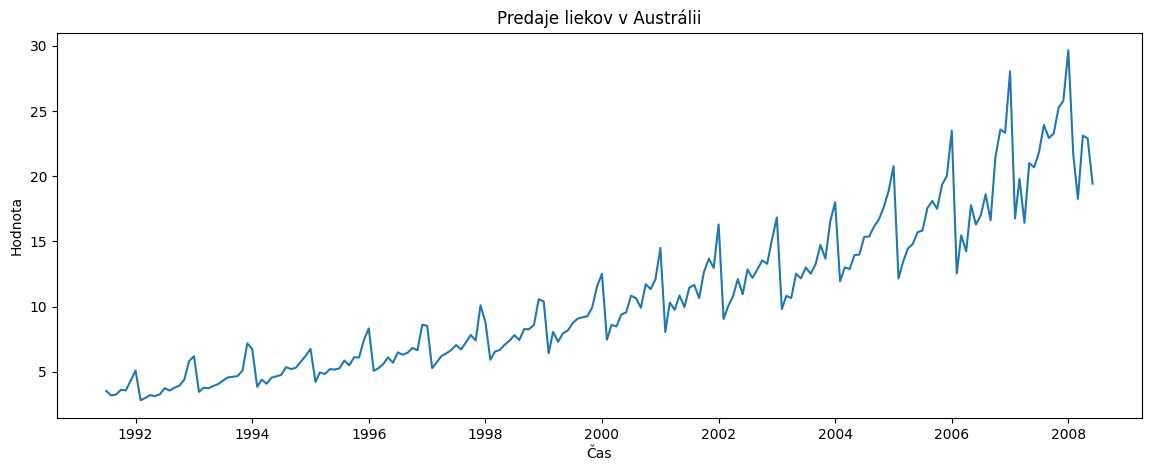

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

data_a10 = pd.read_csv(
    "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv",
    parse_dates=["date"],
    index_col="date"
)

plt.figure(figsize=(14, 5))
plt.plot(data_a10)
plt.xlabel("Čas")
plt.ylabel("Hodnota")
plt.title("Predaje liekov v Austrálii")

plt.show()

### Akú frekvenciu má tento dataset?

Frekvencia určuje význam lagu aj sezónnej periódy.

In [11]:
# TODO: Použite funkciu z knižnice pandas na zistenie frekvencie datasetu.
freq = pd.infer_freq(data_a10.index)
print("Frekvencia datasetu:", freq)
data_a10.index.freq = freq


Frekvencia datasetu: MS


## 2. Agregácia časového Radu

Agregáciou vieme sumarizovať a transformovať dáta cez špecifické intervaly: hodinová, denná, mesačná, kĺzavý priemer. 

In [8]:
# TODO: Vykreslite pôvodné dáta spolu s štvrťročne a ročne agregovanými. 
data_q = data_a10.resample('QE').mean()
data_y = data_a10.resample('YE').mean()

plt.figure(figsize=(14, 6))
plt.plot(data_a10, label="Pôvodné (mesačné)", alpha=0.5, color='gray')
plt.plot(data_q, label="Štvrťročné (agregované)", color='blue', linewidth=2)
plt.plot(data_y, label="Ročné (agregované)", color='red', linewidth=3)

plt.xlabel("Rok")
plt.ylabel("Predaj liekov")
plt.title("Porovnanie pôvodných a agregovaných dát")
plt.legend()
plt.show()

# Ako agregácia ovplyvnila extrémy a sezónne výkyvy? 
# ANSWER: Extrémy sa na štvrťročnom grafe sa zmiernili, ale sezónnosť je stále viditeľná, na ročnom grafe videme že sezónnosť zmizla a krivka sa stala plynulou.

# TODO: Vypočítajte variabilitu pre všetky tri krivky
print("Rozptyl (Variance):")
print("Pôvodné:", data_a10['value'].var())
print("Štvrťročné:", data_q['value'].var())
print("Ročné:", data_y['value'].var())

print("\nSmerodajná odchýlka (Std):")
print("Pôvodné:", data_a10['value'].std())
print("Štvrťročné:", data_q['value'].std())
print("Ročné:", data_y['value'].std())


NameError: name 'data_a10' is not defined

## 3. Trend a sezónnosť

Trend pozorujeme vtedy, keď časový rad vykazuje dlhodobý rast alebo pokles. Sezónnosť pozorujeme vtedy, keď sa v časovom rade opakuje určitý vzor v pravidelných časových intervaloch. Časové rady môžu trend alebo sezónnosť, alebo oboje.

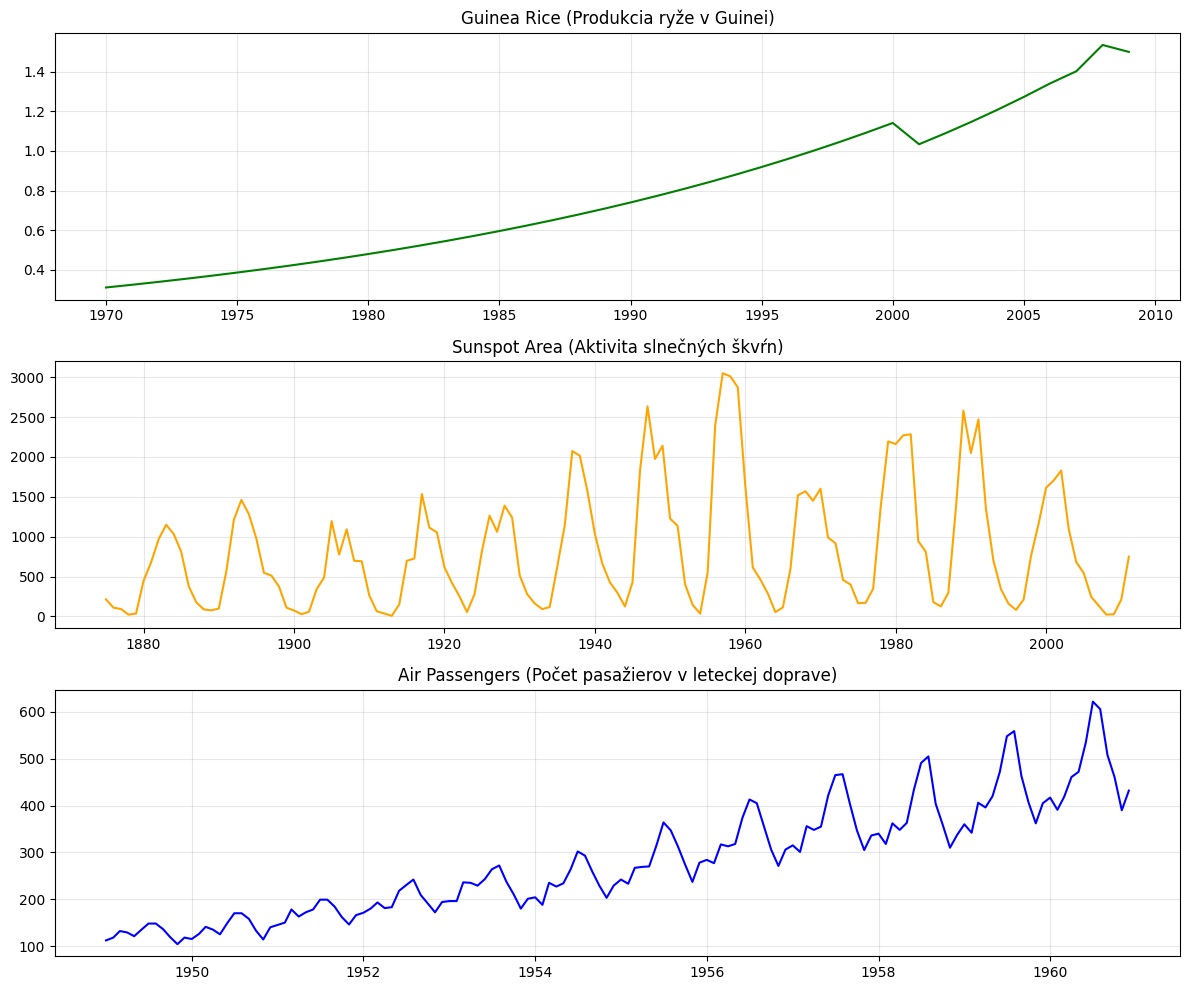

In [ ]:
# TODO: Vykreslite nasledujúce datasety a určite či obsahuje trend, sezónnosť alebo obe zložky
'https://raw.githubusercontent.com/selva86/datasets/master/guinearice.csv'
'https://raw.githubusercontent.com/selva86/datasets/master/sunspotarea.csv'
'https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv'

import pandas as pd
import matplotlib.pyplot as plt

df_rice = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/guinearice.csv', parse_dates=['date'], index_col='date')
df_sun = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/sunspotarea.csv', parse_dates=['date'], index_col='date')
df_air = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/AirPassengers.csv', parse_dates=['date'], index_col='date')

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# Graf 1: Rice
axes[0].plot(df_rice['value'], color='green')
axes[0].set_title('Guinea Rice (Produkcia ryže v Guinei)')
axes[0].grid(True, alpha=0.3)
#videme len trend

# Graf 2: Sunspot
axes[1].plot(df_sun['value'], color='orange')
axes[1].set_title('Sunspot Area (Aktivita slnečných škvŕn)')
axes[1].grid(True, alpha=0.3)
#videme len sezonnost

# Graf 3: AirPassengers
axes[2].plot(df_air['value'], color='blue')
axes[2].set_title('Air Passengers (Počet pasažierov v leteckej doprave)')
axes[2].grid(True, alpha=0.3)
#videme aj trend, aj sezonnost

plt.tight_layout()
plt.show()


## 4. Aditívna a multiplikatívna sezónnosť

Závisiac od datasetu, dáta môžeme modelovať pomocou aditívneho a multiplikatívneho. modelu. Aditívna dekompozícia predpokladá, že sezónne výkyvy majú približne konštantnú absolútnu amplitúdu. Multiplikatívna dekompozícia sa používa, keď sezónne výkyvy rastú spolu s úrovňou dát. 

Frekvencia CO2 datasetu: W-SAT
Sezónny lag (perióda) pre 1 rok = 52 týždňov.



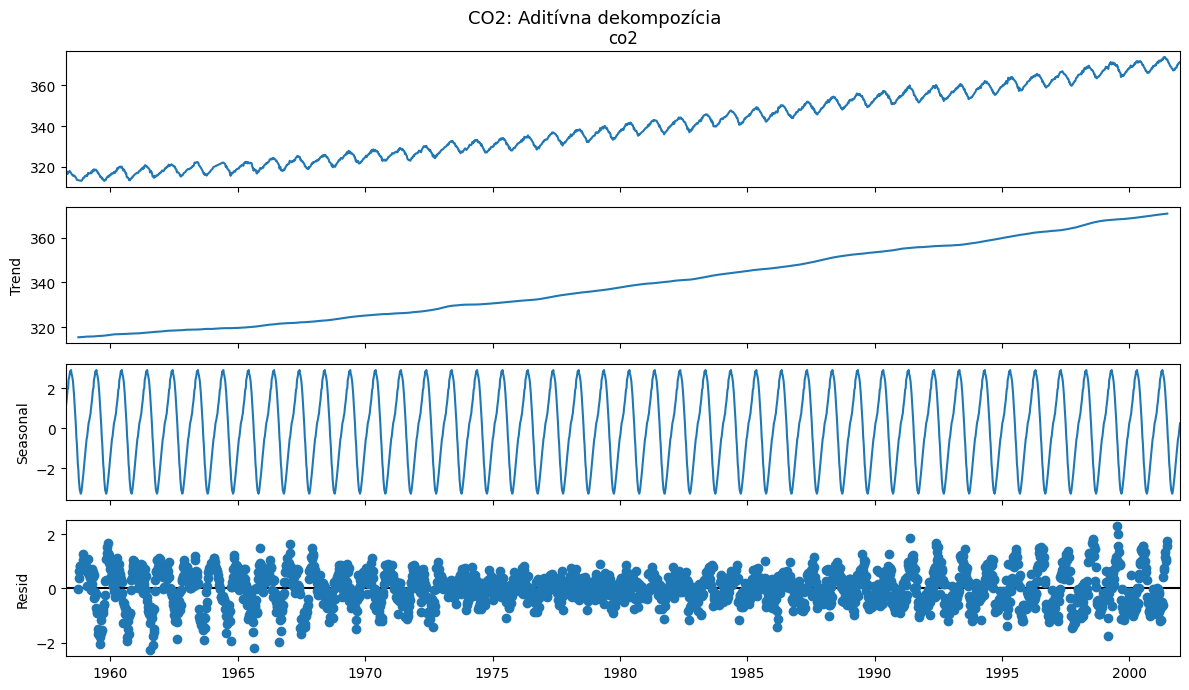

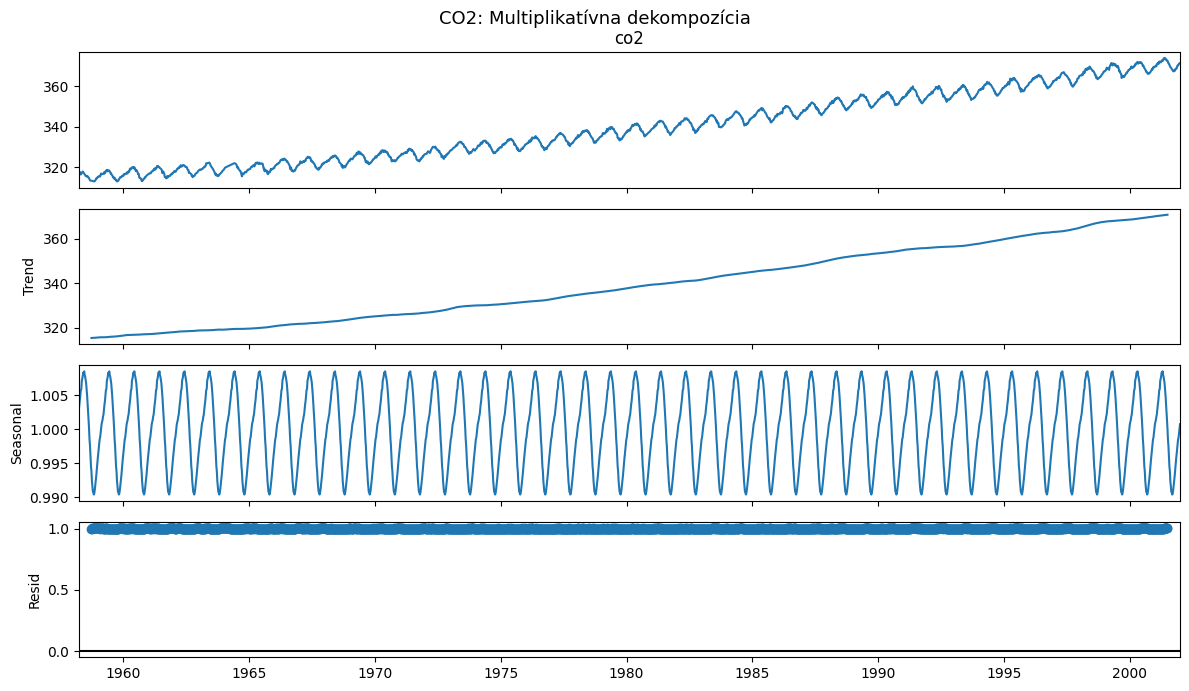

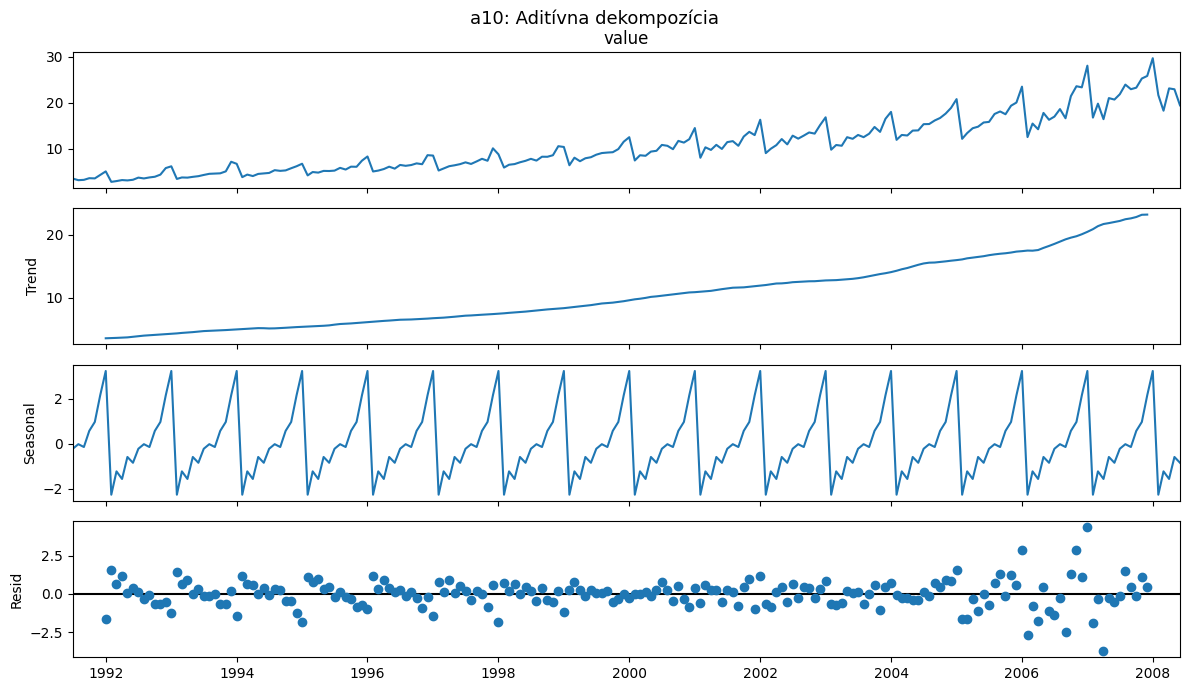

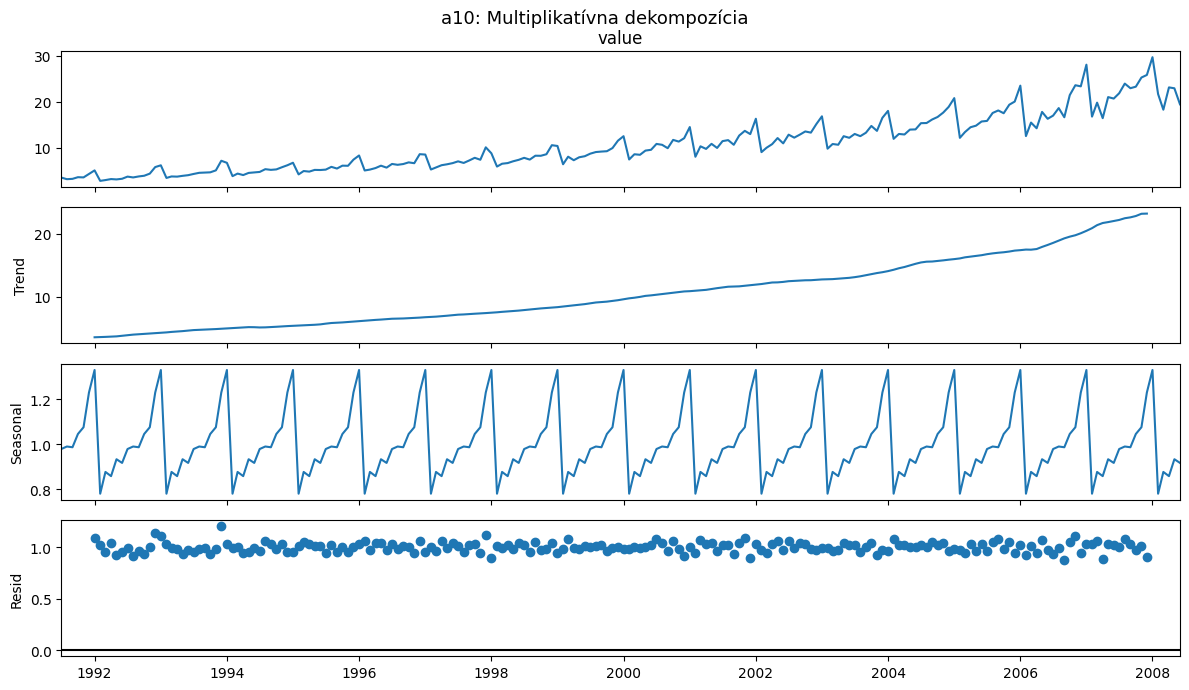

In [5]:
# TODO: Vykonajte aditívny a multiplikatívny model na datasete CO2 a datasete a10. 
# Porovnajte výsledky na grafe.

""" 
Graf by mal obsahovať 4 zložky: pozorovaný rad, trend, sezónnu zložku, rezídium.
Nezabudnite skontrolovať lag CO2 radu.
"""

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.datasets import co2
from statsmodels.tsa.seasonal import seasonal_decompose

data_co2 = co2.load_pandas().data
# Frequency
co2_freq = pd.infer_freq(data_co2.index)
print(f"Frekvencia CO2 datasetu: {co2_freq}")
print("Sezónny lag pre 1 rok = 52 týždňov.\n")

# Interpolacia
data_co2_clean = data_co2.interpolate(method='linear')

# Decomposition (Aditive and multiplicative)
# CO2
res_co2_add = seasonal_decompose(data_co2_clean['co2'], model='additive', period=52)
res_co2_mul = seasonal_decompose(data_co2_clean['co2'], model='multiplicative', period=52)

# a10
res_a10_add = seasonal_decompose(data_a10['value'], model='additive', period=12)
res_a10_mul = seasonal_decompose(data_a10['value'], model='multiplicative', period=12)


#Dataset CO2 (Adit. vs mult.)
fig1 = res_co2_add.plot()
fig1.set_size_inches(12, 7)
fig1.suptitle('CO2: Aditívna dekompozícia', fontsize=13, y=0.98)
fig1.tight_layout()
fig1.subplots_adjust(top=0.92)
plt.show()

fig2 = res_co2_mul.plot()
fig2.set_size_inches(12, 7)
fig2.suptitle('CO2: Multiplikatívna dekompozícia', fontsize=13, y=0.98)
fig2.tight_layout()
fig2.subplots_adjust(top=0.92)
plt.show()

# Dataset a10 (Adit. vs mult.)
fig3 = res_a10_add.plot()
fig3.set_size_inches(12, 7)
fig3.suptitle('a10: Aditívna dekompozícia', fontsize=13, y=0.98)
fig3.tight_layout()
fig3.subplots_adjust(top=0.92)
plt.show()

fig4 = res_a10_mul.plot()
fig4.set_size_inches(12, 7)
fig4.suptitle('a10: Multiplikatívna dekompozícia', fontsize=13, y=0.98)
fig4.tight_layout()
fig4.subplots_adjust(top=0.92)
plt.show()


NameError: name 'res_co2_add' is not defined

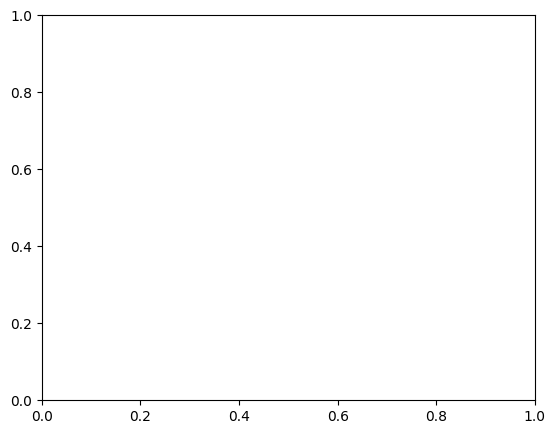

In [ ]:
# TODO: Vytvorte sezónny graf CO2 a a10. 
# Je amplitúda sezónnych výkyvov približne konštantná alebo rastie?
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(res_co2_add.seasonal[:52*3])
plt.title("CO2: Sezónna zložka (Konštantná amplitúda)")
plt.xlabel("Čas")
plt.ylabel("Sezónna odchýlka")

plt.subplot(1, 2, 2)
plt.plot(data_a10['value'])
plt.title("a10: Pôvodný rad (Amplitúda rastie)")
plt.xlabel("Čas")
plt.ylabel("Hodnota")

plt.tight_layout()
plt.show()

# - Pre CO2 je amplitúda sezónnych výkyvov približne KONŠTANTNÁ (vhodný aditívny model).
# - Pre a10 amplitúda sezónnych výkyvov RASTIE spolu s rastom trendu (vhodný multiplikatívny model).


## 5. Stacionarita

 Stacionárny časový rad je taký, ktorého priemer, rozptyl a autokorelácia zostávajú v čase konštantné.
 Predikcie so stacionárnymi radmi sú spoľahlivejšie. 

 Diferencia je jeden zo spôsobov ako zmeniť nestacionárny rad na stacionárny. Ak Y_t je hodnota v čase t, tak prvá diferencia sa vypočíta ako Y_t - Y_t-1. Každá diferencia odoberá informáciu. 


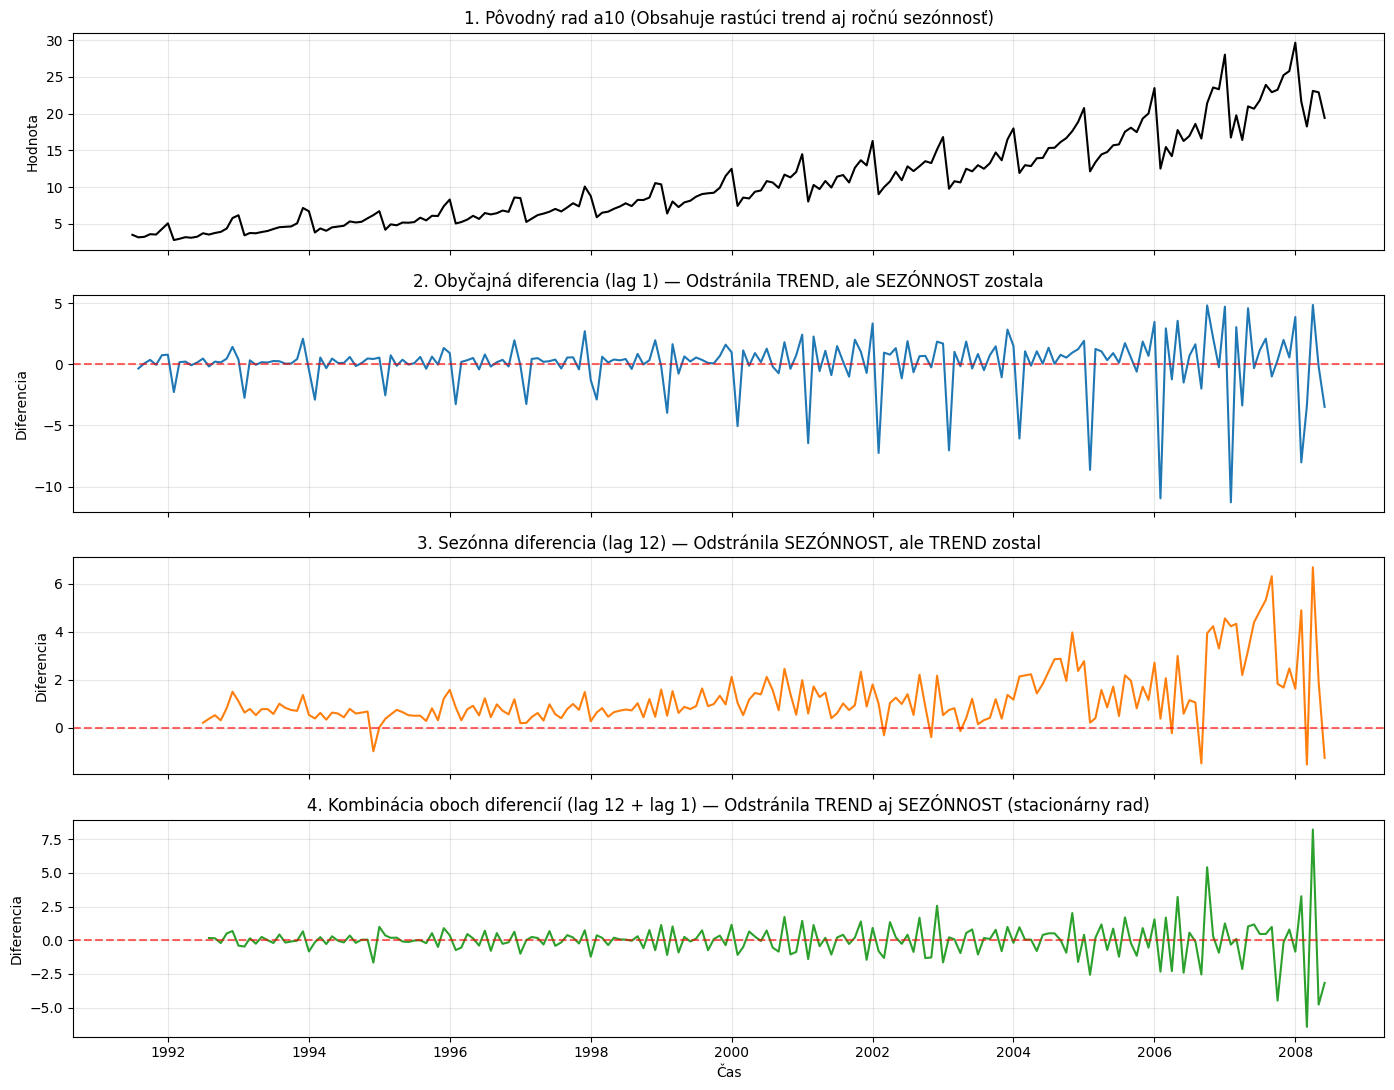

In [ ]:
# TODO: Vykreslite obyčajnú diferenciu, sezónnu diferenciu a kombináciu oboch na datasete a10. 
# Porovnajte výsledky na grafoch. Ktorá diferencia odstránila trend a ktorá sezónnosť?
import matplotlib.pyplot as plt

diff_1 = data_a10['value'].diff(1)             
diff_12 = data_a10['value'].diff(12)           
diff_both = data_a10['value'].diff(12).diff(1)

fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)

# 1. Pôvodný rad
axes[0].plot(data_a10['value'], color='black')
axes[0].set_title("1. Pôvodný rad a10 (Obsahuje rastúci trend aj ročnú sezónnosť)")
axes[0].set_ylabel("Hodnota")
axes[0].grid(True, alpha=0.3)

# 2. Obyčajná diferencia
axes[1].plot(diff_1, color='tab:blue')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[1].set_title("2. Obyčajná diferencia (lag 1) — Odstránila TREND, ale SEZÓNNOST zostala")
axes[1].set_ylabel("Diferencia")
axes[1].grid(True, alpha=0.3)

# 3. Sezónna diferencia
axes[2].plot(diff_12, color='tab:orange')
axes[2].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[2].set_title("3. Sezónna diferencia (lag 12) — Odstránila SEZÓNNOST, ale TREND zostal")
axes[2].set_ylabel("Diferencia")
axes[2].grid(True, alpha=0.3)

# 4. Kombinácia oboch diferencií
axes[3].plot(diff_both, color='tab:green')
axes[3].axhline(0, color='red', linestyle='--', alpha=0.6)
axes[3].set_title("4. Kombinácia oboch diferencií (lag 12 + lag 1) — Odstránila TREND aj SEZÓNNOST (stacionárny rad)")
axes[3].set_xlabel("Čas")
axes[3].set_ylabel("Diferencia")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# - Obyčajná diferencia (lag = 1) odstránila TREND (hodnoty oscilujú okolo nuly), no sezónne výkyvy pretrvávajú.
# - Sezónna diferencia (lag = 12) odstránila SEZÓNNOST (odstránil sa ročný cyklus), no rastúci trend v dátach zostal.
# - Kombinácia oboch diferencií (obyčajná + sezónna) odstránila obidve zložky naraz a priviedla rad k stacionarite.


## 6. Testovanie stacionarity

Ak si nie sme istí vizuálnym odhadom, použijeme ADF (Augmented Dickey-Fuller) test alebo KPSS (Kwiatkowski-Phillips-Schmidt-Shin) test. 

ADF nulová hypotéza tvrdí, že časový rad obsahuje jednotkový koreň, a teda je nestacionárny. Ak je p hodnota menšia ako zvolená hladina významnosti, nulovú hypotézu zamietame a časový rad považujeme za stacionárny.

In [ ]:
# TODO: Porovnajte stacionaritu a10 a CO2 datasetu pomocou ADF pred a po použití diferencie. 
# Kde je potrebné kombinovať obyčajnú aj sezónnu?

import pandas as pd
from IPython.display import display
from statsmodels.tsa.stattools import adfuller

def adf_test(series, name):
    res = adfuller(series.dropna())
    adf_stat = res[0]
    p_value = res[1]
    crit_5 = res[4]['5%']
    is_stationary = p_value < 0.05
    return {
        "Rad": name,
        "ADF Štatistika": f"{adf_stat:.4f}",
        "p-hodnota": f"{p_value:.4e}",
        "Kritická h. (5%)": f"{crit_5:.4f}",
        "Stacionárny (p < 0.05)?": "Áno" if is_stationary else "Nie"
    }

a10_orig = data_a10['value']
a10_diff1 = a10_orig.diff(1)
a10_diff12 = a10_orig.diff(12)
a10_diff_both = a10_orig.diff(12).diff(1)

co2_orig = data_co2_clean['co2']
co2_diff1 = co2_orig.diff(1)
co2_diff52 = co2_orig.diff(52)
co2_diff_both = co2_orig.diff(52).diff(1)

tests = [
    (a10_orig, "a10: Pôvodný rad"),
    (a10_diff1, "a10: Obyčajná diferencia (diff(1))"),
    (a10_diff12, "a10: Sezónna diferencia (diff(12))"),
    (a10_diff_both, "a10: Obe diferencie (diff(12) + diff(1))"),
    (co2_orig, "CO2: Pôvodný rad"),
    (co2_diff1, "CO2: Obyčajná diferencia (diff(1))"),
    (co2_diff52, "CO2: Sezónna diferencia (diff(52))"),
    (co2_diff_both, "CO2: Obe diferencie (diff(52) + diff(1))")
]

results = [adf_test(s, name) for s, name in tests]
df_results = pd.DataFrame(results)

display(df_results)

# Kde je potrebné kombinovať obyčajnú aj sezónnu diferenciu?
# a10 - potrebujem kombinovat


/tmp/ipykernel_4934/1493870071.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series.dropna())
/tmp/ipykernel_4934/1493870071.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series.dropna())
/tmp/ipykernel_4934/1493870071.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag ar

,Rad,ADF Štatistika,p-hodnota,Kritická h. (5%),Stacionárny (p < 0.05)?
0,a10: Pôvodný rad,3.1452,1.0000e+00,-2.8770,Nie
1,a10: Obyčajná diferencia (diff(1)),-2.4952,1.1665e-01,-2.8771,Nie
2,a10: Sezónna diferencia (diff(12)),-2.0927,2.4745e-01,-2.8779,Nie
3,a10: Obe diferencie (diff(12) + diff(1)),-4.7834,5.8495e-05,-2.8779,Áno
4,CO2: Pôvodný rad,0.0338,9.6124e-01,-2.8628,Nie
5,CO2: Obyčajná diferencia (diff(1)),-15.7275,1.3013e-28,-2.8628,Áno
6,CO2: Sezónna diferencia (diff(52)),-5.5312,1.7860e-06,-2.8628,Áno
7,CO2: Obe diferencie (diff(52) + diff(1)),-17.1904,6.5580e-30,-2.8628,Áno


## 7. Autokorelácia

Autokorelácia meria lineárnu závislosť medzi hodnotami oddelenými lagom. 

Ak časový rad obsahuje trend, autokorelácia pri malých lagoch býva vysoká a kladná, pretože pozorovania, ktoré sú časovo blízke, majú zvyčajne aj podobné hodnoty. ACF časového radu s trendom preto často nadobúda kladné hodnoty, ktoré sa so zvyšujúcim oneskorením postupne znižujú.
Ak údaje obsahujú sezónnosť, vyššie hodnoty autokorelácie sa objavujú pri sezónnych lagoch. Napríklad pri mesačných údajoch s ročnou sezónnosťou môžeme očakávať vyššiu autokoreláciu pri lagoch 12, 24, 36 atď.
Ak časový rad obsahuje trend aj sezónnosť, v ACF môžeme pozorovať kombináciu oboch javov.

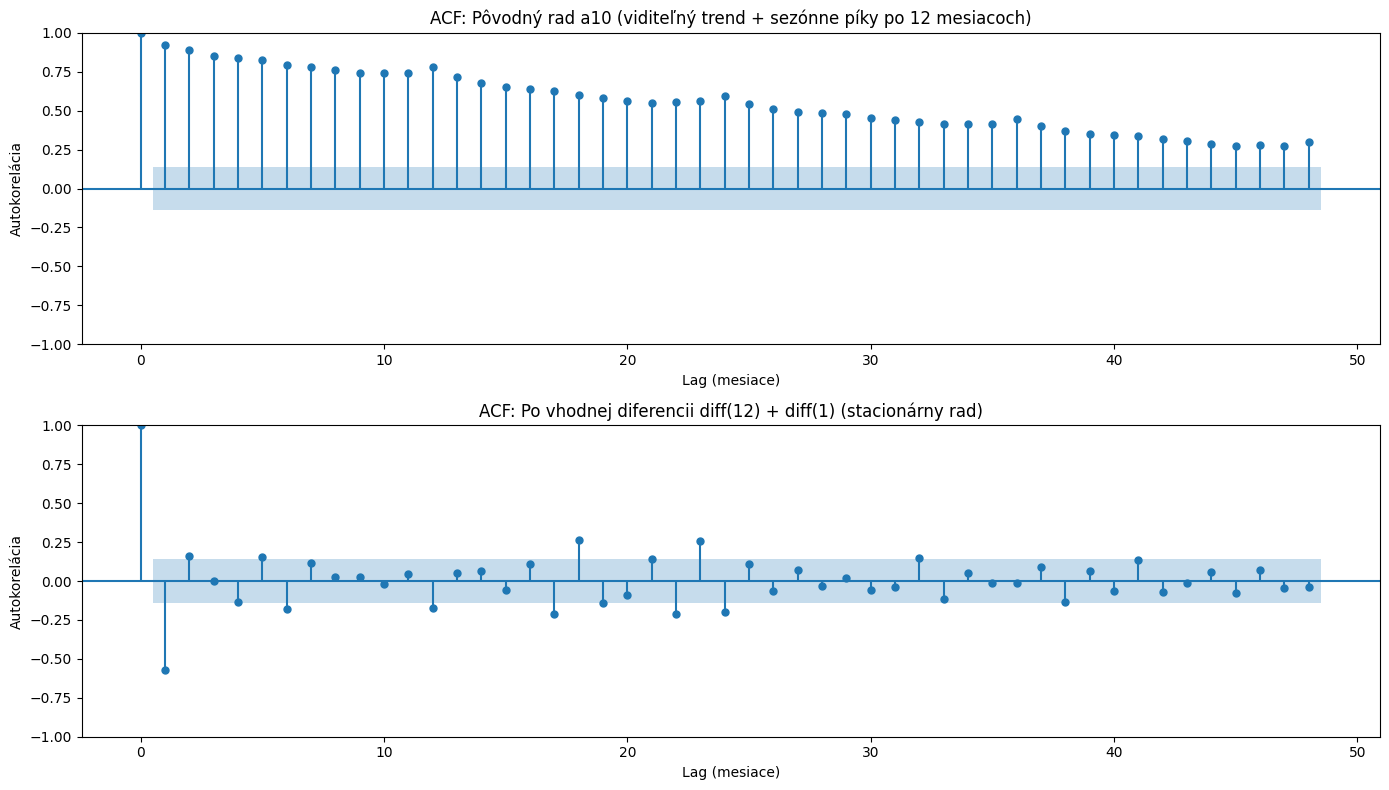

In [19]:
# TODO: Vykreslite ACF pôvodného radu a10 a ACF po vhodnej diferencii. 
# Pridajte do funkcie plot_acf parameter bartlett_confint=False pre vykreslenie fixného konfidenčného pásma.

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

a10_orig = data_a10['value']
a10_diff_suitable = a10_orig.diff(12).diff(1).dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(
    a10_orig, 
    ax=axes[0], 
    lags=48, 
    bartlett_confint=False, 
    title="ACF: Pôvodný rad a10 (viditeľný trend + sezónne píky po 12 mesiacoch)"
)
axes[0].set_xlabel("Lag (mesiace)")
axes[0].set_ylabel("Autokorelácia")

plot_acf(
    a10_diff_suitable, 
    ax=axes[1], 
    lags=48, 
    bartlett_confint=False, 
    title="ACF: Po vhodnej diferencii diff(12) + diff(1) (stacionárny rad)"
)
axes[1].set_xlabel("Lag (mesiace)")
axes[1].set_ylabel("Autokorelácia")

plt.tight_layout()
plt.show()

# Komentár k interpretácii:
# 1. Pôvodný rad: ACF klesá veľmi pomaly (prítomnosť trendu) a na lagoch 12, 24, 36, 48
#    vidíme výrazné lokálne maximá (prítomnosť 12-mesačnej sezónnosti) -> rad je nestacionárny.
# 2. Po diferencii diff(12) + diff(1): Hodnoty ACF okamžite klesajú do konfidenčného pásma
#    (modrá oblasť), čo potvrdzuje, že rad bol úspešne stacionarizovaný.


## BONUS - 2 body

1. S datasetom a10 vykreslite 3 zložky časového radu pomocou STL (Seasonal and Trend decomposition using Loess). Keďže STL je aditívny, nezabudnite určiť, či dataset nepotrebuje logaritmickou transformáciu. Vyskúšajte STL bez logaritmickej transformácie. 

2. Aplikujte Box-Cox transformáciu. Aká je hodnota λ? Vysvetlite rozdiel medzi Box-Cox a diferenciou.

3. Otestujte dataset s KPSS testom. Vysvetli rozdiel medzi ADF a KPSS.


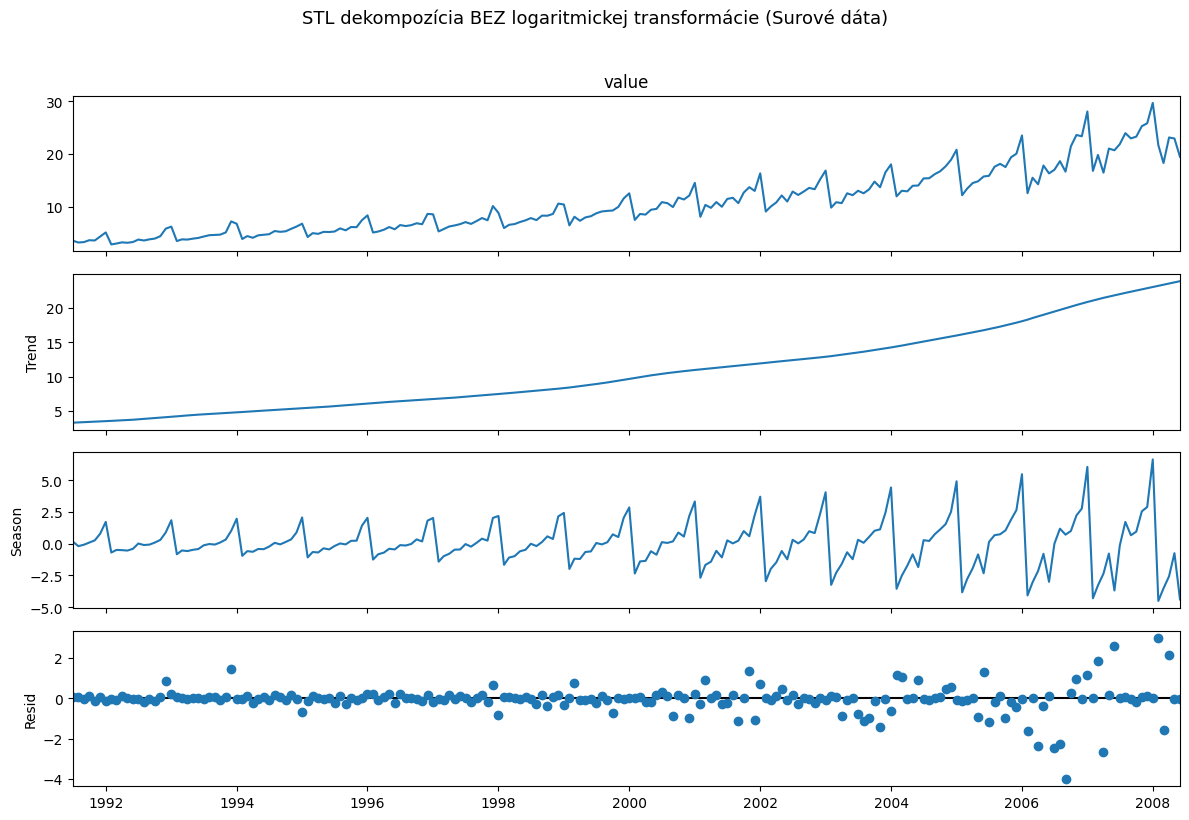

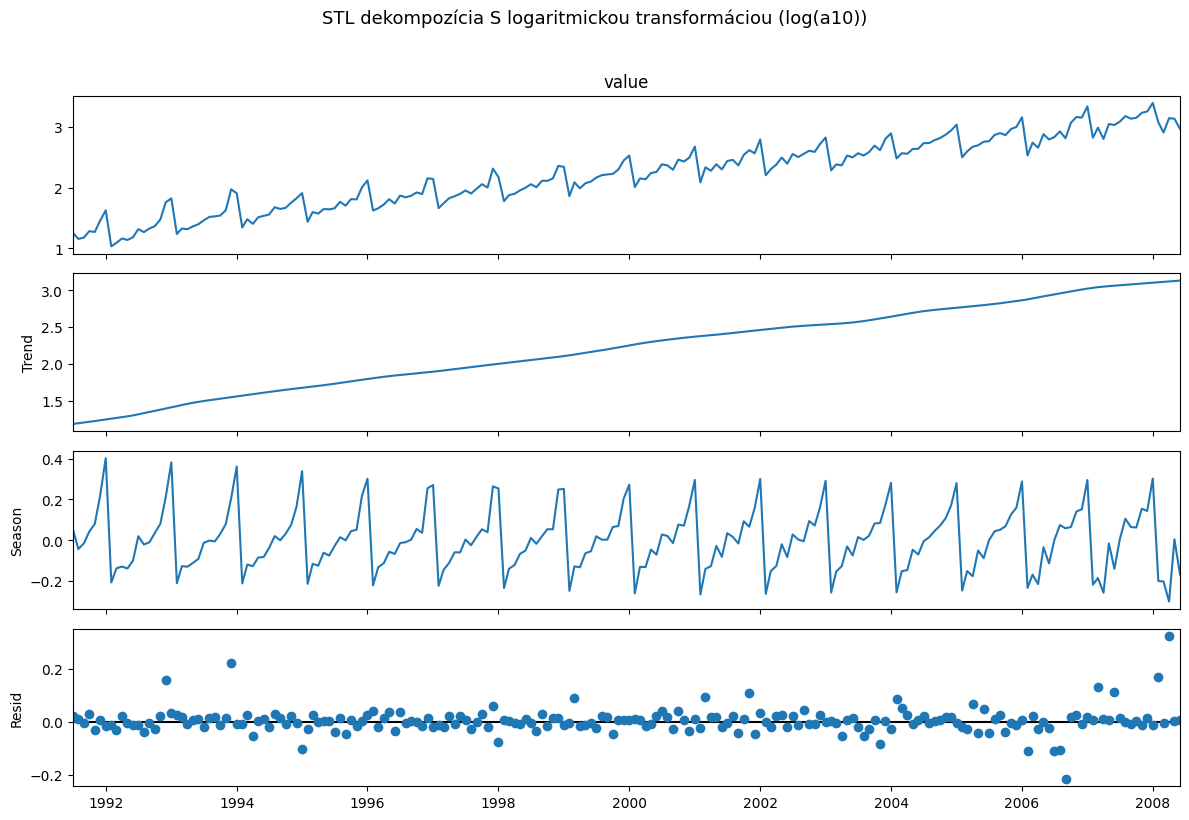

In [ ]:
#1 Zadanie
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

data_a10.index.freq = 'MS'

#no log
stl_raw = STL(data_a10['value'], period=12, robust=True).fit()
fig_raw = stl_raw.plot()
fig_raw.set_size_inches(12, 8)
fig_raw.suptitle("STL dekompozícia bez logaritmickej transformácie (Surové dáta)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

#np.log
stl_log = STL(np.log(data_a10['value']), period=12, robust=True).fit()
fig_log = stl_log.plot()
fig_log.set_size_inches(12, 8)
fig_log.suptitle("STL dekompozícia s logaritmickou transformáciou (log(a10))", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# Odpoveď na otázky zo zadania:
# ==============================================================================
# 1. Potrebuje dataset logaritmickú transformáciu?
#    ÁNO. Dataset a10 vykazuje multiplikatívny charakter – amplitúda (rozptyl) sezónnych výkyvov 
#    rastie priamo úmerne s rastúcim trendom (v roku 1991 bol výkyv ~2, v roku 2007 už ~10). 
#    Keďže STL je čisto aditívny model (Y = Trend + Season + Resid), logaritmická transformácia 
#    prevedie násobenie na sčítanie: log(Y) = log(Trend) + log(Season) + log(Resid), čím stabilizuje rozptyl.
#
# 2. Čo pozorujeme pri STL BEZ logaritmickej transformácie?
#    - Sezónna zložka má konštantnú amplitúdu pre celé obdobie (priemer).
#    - V skorších rokoch (1991–1996) je odhadnutá sezónnosť príliš veľká oproti realite.
#    - V neskorších rokoch (2004–2008) je odhadnutá sezónnosť príliš malá a nestačí pokrývať skutočné píky.
#    - Dôsledok: V zložke rezíduí (Resid) je zrejmá heteroskedasticita (rozptyl rezíduí dramaticky rastie 
#      v čase) a v rezíduách zostáva nevyčerpaná sezónnosť – rezíduá teda nie sú bielym šumom!
#
# 3. Po aplikácii logaritmu:
#    - Rozptyl rezíduí je stabilný a homogénny v celom časovom horizonte (homoskedasticita).
#    - Rezíduá sa správajú ako náhodný biely šum.


Optimálna hodnota lambda (λ): 0.0615


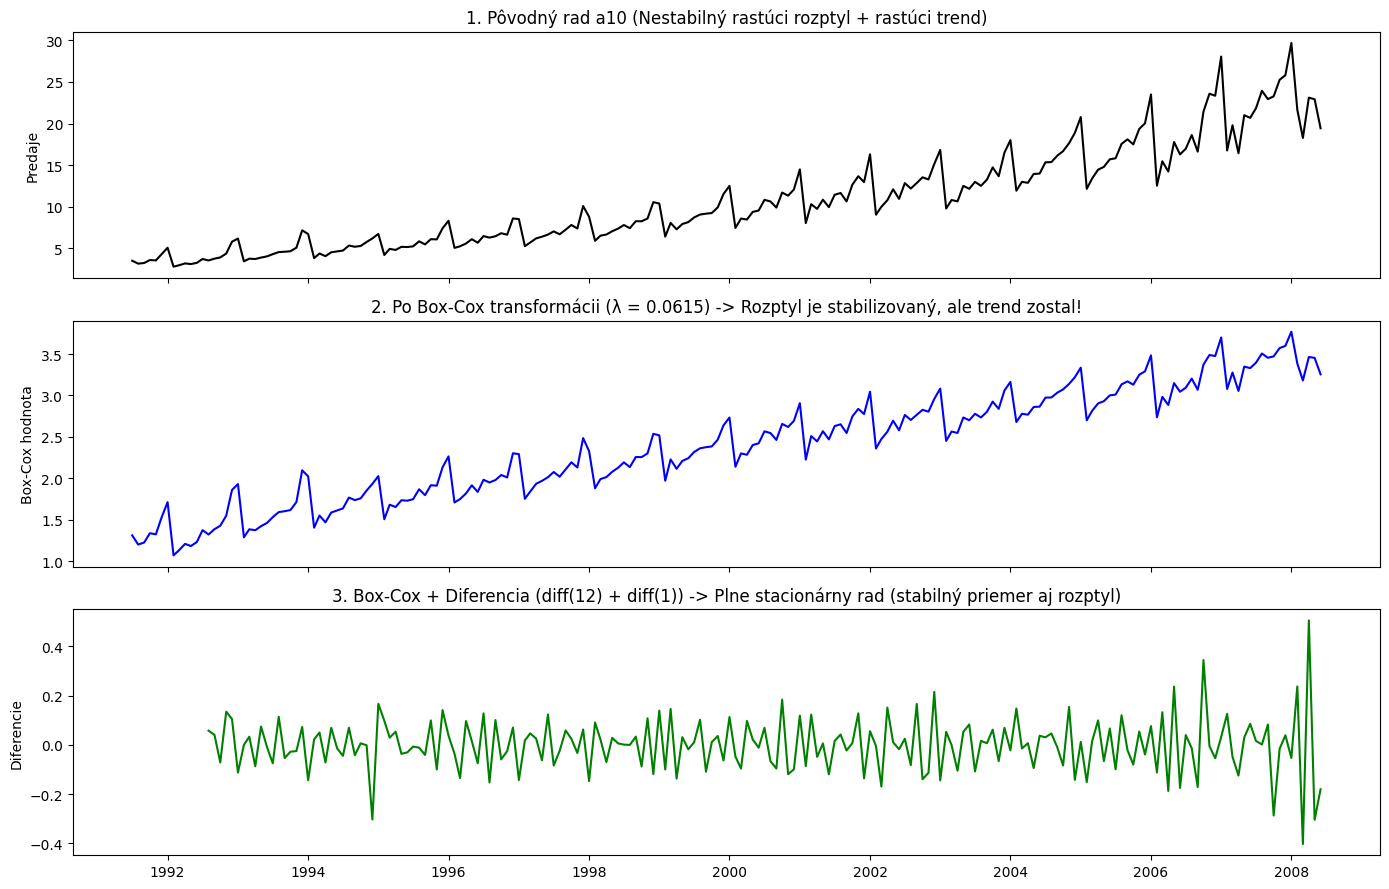

In [ ]:
#2 Zadanie
import matplotlib.pyplot as plt
from scipy.stats import boxcox

boxcox_values, lmbda = boxcox(data_a10['value'])
data_a10['boxcox'] = boxcox_values
print(f"Optimálna hodnota lambda (λ): {lmbda:.4f}")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axes[0].plot(data_a10['value'], color='black')
axes[0].set_title("1. Pôvodný rad a10 (Nestabilný rastúci rozptyl + rastúci trend)")
axes[0].set_ylabel("Predaje")

axes[1].plot(data_a10['boxcox'], color='blue')
axes[1].set_title(f"2. Po Box-Cox transformácii (λ = {lmbda:.4f}) -> Rozptyl je stabilizovaný, ale trend zostal!")
axes[1].set_ylabel("Box-Cox hodnota")

bc_diff = data_a10['boxcox'].diff(12).diff(1).dropna()
axes[2].plot(bc_diff, color='green')
axes[2].set_title("3. Box-Cox + Diferencia (diff(12) + diff(1)) -> Plne stacionárny rad (stabilný priemer aj rozptyl)")
axes[2].set_ylabel("Diferencie")

plt.tight_layout()
plt.show()

# ==============================================================================
# Odpovede na otázky zo zadania:
# ==============================================================================
# 1. Aká je hodnota λ?
#    Optimálna hodnota lambda odhadnutá metódou maximálnej vierohodnosti (MLE) je λ ≈ 0.0615.
#    Keďže je hodnota veľmi blízka 0, matematicky to potvrdzuje, že logaritmická 
#    transformácia (pre ktorú platí λ = 0) je pre dataset a10 ideálna.
#
# 2. Aký je rozdiel medzi Box-Cox transformáciou a diferenciou?
#    - Box-Cox transformácia slúži na stabilizáciu ROZPTYLU (variance):
#      Mení mierku jednotlivých hodnôt Y_t a eliminuje závislosť veľkosti výkyvov od úrovne radu.
#      NEODSTRAŇUJE trend ani sezónnosť (rad po Box-Cox má stále rastúci trend).
#      Nestráca žiadne pozorovania.
#
#    - Diferencia slúži na stabilizáciu STREDNEJ HODNOTY (mean):
#      Odstraňuje trend (obyčajná diferencia) a sezónny cyklus (sezónna diferencia).
#      NEVIE stabilizovať rastúci rozptyl (ak je rozptyl nestabilný, diferencie budú mať stále 
#      rastúcu amplitúdu).
#      Pri každom ráde diferencie prichádzame o pozorovania (vznikajú NaN).
#
#    V praxi (metodika Box-Jenkins / ARIMA) sa tieto techniky dopĺňajú:
#    Najprv sa aplikuje Box-Cox (alebo log) na stabilizáciu rozptylu, a následne 
#    diferencia na odstránenie trendu a dosiahnutie plnej stacionarity.


In [ ]:
#3 Zadanie
import pandas as pd
import warnings
from statsmodels.tsa.stattools import kpss, adfuller
warnings.filterwarnings("ignore")

s_orig = data_a10['value']
s_diff1 = s_orig.diff(1).dropna()
s_diff12 = s_orig.diff(12).dropna()
s_both = s_orig.diff(12).diff(1).dropna()

tests = [
    (s_orig, "a10: Pôvodný rad"),
    (s_diff1, "a10: Obyčajná diff(1)"),
    (s_diff12, "a10: Sezónna diff(12)"),
    (s_both, "a10: Obe diferencie diff(12) + diff(1)")
]

def run_stationarity_tests(series, name):
    k_stat, k_pval, _, k_crit = kpss(series, regression='c', nlags='auto')
    kpss_stationary = k_pval >= 0.05
    
    a_res = adfuller(series)
    a_stat, a_pval = a_res[0], a_res[1]
    adf_stationary = a_pval < 0.05
    
    return {
        "Rad": name,
        "ADF p-hodnota": f"{a_pval:.4e}",
        "ADF záver": "Stacionárny" if adf_stationary else "Nestacionárny",
        "KPSS Štatistika": f"{k_stat:.4f}",
        "KPSS p-hodnota": f"{k_pval:.4f}",
        "KPSS záver": "Stacionárny" if kpss_stationary else "Nestacionárny",
        "Celkový konsenzus": "STACIONÁRNY" if (adf_stationary and kpss_stationary) else ("NESTACIONÁRNY" if (not adf_stationary and not kpss_stationary) else "Nejednoznačný")
    }

results = [run_stationarity_tests(s, name) for s, name in tests]
df_stationarity = pd.DataFrame(results)

df_stationarity


,Rad,ADF p-hodnota,ADF záver,KPSS Štatistika,KPSS p-hodnota,KPSS záver,Celkový konsenzus
0,a10: Pôvodný rad,1.0000e+00,Nestacionárny,2.0131,0.0100,Nestacionárny,NESTACIONÁRNY
1,a10: Obyčajná diff(1),1.1665e-01,Nestacionárny,0.1341,0.1000,Stacionárny,Nejednoznačný
2,a10: Sezónna diff(12),2.4745e-01,Nestacionárny,1.1761,0.0100,Nestacionárny,NESTACIONÁRNY
3,a10: Obe diferencie diff(12) + diff(1),5.8495e-05,Stacionárny,0.1071,0.1000,Stacionárny,STACIONÁRNY
